# Loading libraries

In [1]:
import numpy as np
import time
import itertools
import warnings
import matplotlib.pyplot as plt
from IPython.display import display


# Define transition matrix

In [2]:
def build_M(n):
    strains = list(range(n))
    subsets = []

    for r in range(n+1):
        for comb in itertools.combinations(strains, r):
            subsets.append(set(comb))

    num = len(subsets)
    M = np.zeros((num, n))

    for a, J in enumerate(subsets):
        for i in strains:
            if i not in J:
                M[a, i] = 1

    return M, subsets

# Define cross-immunity matrix

In [3]:
def build_sigma(n, eps, subsets):
    num = len(subsets)
    sigma = np.zeros((num, n))

    for a, J in enumerate(subsets):
        for i in range(n):
            if len(J) == 0:
                sigma[a, i] = 1
            elif i in J:
                sigma[a, i] = 0
            else:
                sigma[a, i] = 1 - eps

    return sigma

# Building transition map

In [4]:
def build_add_to_history_map(subsets, n):

    num = len(subsets)

    index_map = {frozenset(J): idx for idx, J in enumerate(subsets)}

    next_mask = np.zeros((num, n), dtype=np.int64)
    for a, J in enumerate(subsets):
        for i in range(n):
            newJ = set(J)
            newJ.add(i)
            next_mask[a, i] = index_map[frozenset(newJ)]
    return next_mask

# Set-Based ODE

In [5]:
def rhs_set_based(S, I, beta, sigma, gamma, mu, b, n, subsets):
    num = len(subsets)

    Lambda = np.zeros(n, dtype=np.float64)
    for i in range(n):
        total = 0.0
        for a, J in enumerate(subsets):
            if i not in J:
                total += I[a, i]
        Lambda[i] = beta[i] * total

    dI = np.zeros_like(I)
    for a in range(num):
        Sa = S[a]
        for i in range(n):
            Lambda_clip = np.clip(Lambda[i], 0, 1e10)
            Sa_clip = np.clip(Sa, 0, None)
            dI[a, i] = sigma[a, i] * Lambda_clip * Sa_clip - (gamma + mu) * I[a, i]

    dS = np.zeros_like(S)
    dS[0] += b

    #infection out + death
    for a, J in enumerate(subsets):
        inf_out = 0.0
        for i in range(n):
            if i not in J:
                inf_out += sigma[a, i] * Lambda[i] * S[a]
        dS[a] -= inf_out
        dS[a] -= mu * S[a]

    #recovery
    next_mask = build_add_to_history_map(subsets, n)
    for a in range(num):
        for i in range(n):
            dS[next_mask[a, i]] += gamma * I[a, i]

    return dS, dI

# Matrix-based ODE

In [6]:
def rhs_matrix_based(S, I, beta, sigma, M, next_mask, gamma, mu, b):

    J = np.diag(M.T @ I)
    Lambda = beta * J

    incidence = sigma * (S[:, None] * Lambda[None, :])

    dI = incidence - (gamma + mu) * I

    dS = np.zeros_like(S)
    dS[0] += b

    inf_out = np.sum(M * incidence, axis=1)
    dS -= inf_out
    dS -= mu * S

    for i in range(I.shape[1]):
        np.add.at(dS, next_mask[:, i], gamma * I[:, i])

    return dS, dI

# Simulation function

In [7]:
def simulate(method, n, T=200, dt=0.5, repeats=3, eps=0.2, seed=0):

    rng = np.random.default_rng(seed)
    num = 2**n

    beta = np.linspace(0.25, 0.50, n)
    gamma = 1/7
    mu = 1/(70*365)
    b = 1.0

    M, subsets = build_M(n)
    sigma = build_sigma(n, eps, subsets)

    S0 = np.zeros(num, dtype=np.float64)
    S0[0] = 1_000.0
    I0 = np.zeros((num, n), dtype=np.float64)

    I0[0, :] = rng.uniform(0.5, 2.0, size=n)
    S0[0] -= np.sum(I0[0, :])

    if method == "matrix":
        M, subsets = build_M(n)
        next_mask = build_add_to_history_map(subsets, n)
    else:
        M = None
        next_mask = None

    times = []
    steps = int(T / dt)

    for r in range(repeats):
        S = S0.copy()
        I = I0.copy()

        start = time.perf_counter()
        for _ in range(steps):
            if method == "set":
                dS, dI = rhs_set_based(S, I, beta, sigma, gamma, mu, b, n, subsets)
            else:
                dS, dI = rhs_matrix_based(S, I, beta, sigma, M, next_mask, gamma, mu, b)
            S += dt * dS
            I += dt * dI

            S = np.maximum(S, 0.0)
            I = np.maximum(I, 0.0)

        end = time.perf_counter()
        times.append(end - start)

    return float(np.mean(times)), float(np.std(times))

# Benchmark and visualisation

/tmp/ipykernel_482/545544353.py:6: RuntimeWarning: overflow encountered in multiply
  incidence = sigma * (S[:, None] * Lambda[None, :])
/tmp/ipykernel_482/545544353.py:6: RuntimeWarning: invalid value encountered in multiply
  incidence = sigma * (S[:, None] * Lambda[None, :])


n= 2 | set=0.025s ±0.001 | matrix=0.010s ±0.003 | speedup=2.47x
n= 3 | set=0.069s ±0.003 | matrix=0.011s ±0.001 | speedup=6.09x


/tmp/ipykernel_482/545544353.py:3: RuntimeWarning: invalid value encountered in matmul
  J = np.diag(M.T @ I)


n= 4 | set=0.175s ±0.010 | matrix=0.010s ±0.000 | speedup=17.28x
n= 5 | set=0.419s ±0.011 | matrix=0.013s ±0.001 | speedup=31.68x
n= 6 | set=1.005s ±0.009 | matrix=0.013s ±0.000 | speedup=76.79x
n= 7 | set=2.498s ±0.294 | matrix=0.016s ±0.000 | speedup=153.57x
n= 8 | set=5.518s ±0.284 | matrix=0.022s ±0.001 | speedup=250.44x


/usr/local/lib/python3.12/dist-packages/numpy/_core/fromnumeric.py:86: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/tmp/ipykernel_482/545544353.py:3: RuntimeWarning: overflow encountered in matmul
  J = np.diag(M.T @ I)


n= 9 | set=12.496s ±0.204 | matrix=0.039s ±0.006 | speedup=322.50x
n=10 | set=27.341s ±0.318 | matrix=0.052s ±0.000 | speedup=525.57x
n=11 | set=60.103s ±0.345 | matrix=0.108s ±0.004 | speedup=557.95x


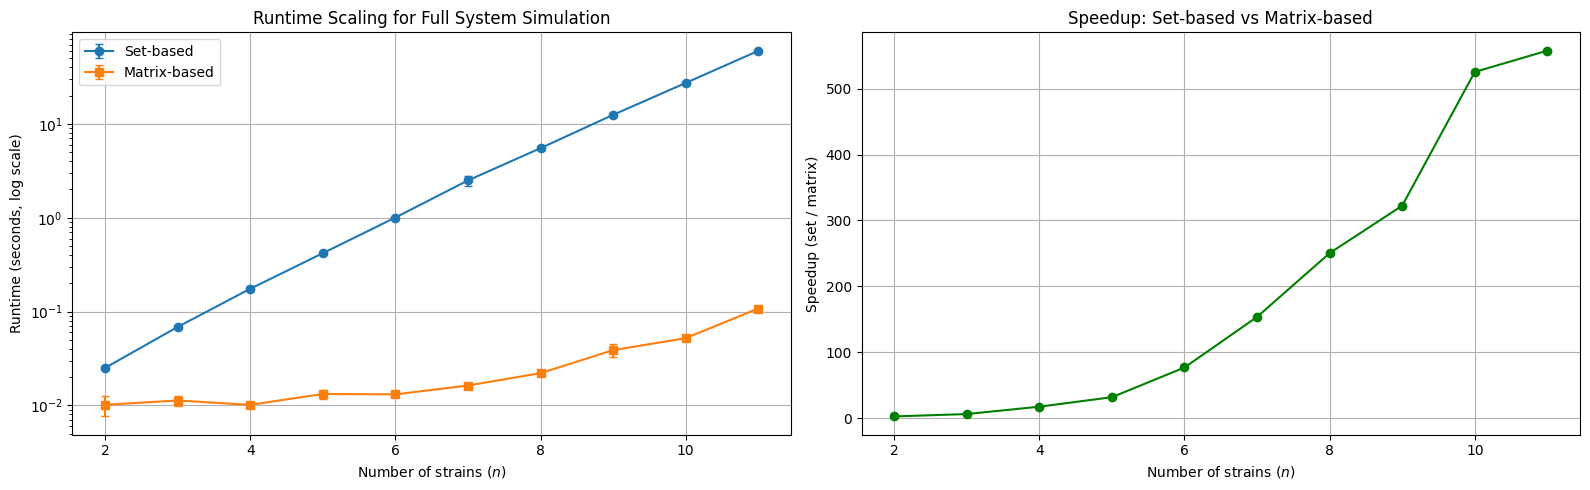

In [8]:
def benchmark_across_n(n_list, T=200, dt=0.5, repeats=3):
    rt_set, sd_set = [], []
    rt_mat, sd_mat = [], []

    for n in n_list:
        t1, s1 = simulate("set", n, T=T, dt=dt, repeats=repeats, seed=0)
        t2, s2 = simulate("matrix", n, T=T, dt=dt, repeats=repeats, seed=0)

        rt_set.append(t1); sd_set.append(s1)
        rt_mat.append(t2); sd_mat.append(s2)

        print(f"n={n:2d} | set={t1:.3f}s ±{s1:.3f} | matrix={t2:.3f}s ±{s2:.3f} | speedup={t1/t2:.2f}x")

    return np.array(rt_set), np.array(sd_set), np.array(rt_mat), np.array(sd_mat)

n_list = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
rt_set, sd_set, rt_mat, sd_mat = benchmark_across_n(n_list, T=150, dt=0.5, repeats=3)

speedup = rt_set / rt_mat

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].errorbar(n_list, rt_set, yerr=sd_set, marker='o', capsize=3, label='Set-based')
axes[0].errorbar(n_list, rt_mat, yerr=sd_mat, marker='s', capsize=3, label='Matrix-based')
axes[0].set_yscale('log')
axes[0].set_xlabel(r'Number of strains ($n$)')
axes[0].set_ylabel('Runtime (seconds, log scale)')
axes[0].set_title('Runtime Scaling for Full System Simulation')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(n_list, speedup, marker='o', color='green')
axes[1].set_xlabel(r'Number of strains ($n$)')
axes[1].set_ylabel('Speedup (set / matrix)')
axes[1].set_title('Speedup: Set-based vs Matrix-based')
axes[1].grid(True)

plt.tight_layout()
plt.show()
